# [9660] Logistic Regression 2
Data file:
* https://raw.githubusercontent.com/vjavaly/Baruch-CIS-9660/main/data/Pima_diabetes.csv

In [1]:
from datetime import datetime
print(f'Run time: {datetime.now().strftime("%D %T")}')

Run time: 10/20/26 18:48:42


### Import libraries

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn import metrics


In [3]:
import statsmodels.formula.api as smf

### Load data

In [4]:
# You can download the original data set from
#  https://www.kaggle.com/uciml/pima-indians-diabetes-database/data
df = pd.read_csv('https://raw.githubusercontent.com/vjavaly/Baruch-CIS-9660/main/data/Pima_diabetes.csv')
df.shape

(768, 9)

### Examine data

In [5]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Notes:  
1) Target variable: Outcome  
2) Notice zero values for blood pressure, skin thickness, insulin, BMI, etc.  Ignore for now.  

In [6]:
# Check for missing values (nulls)
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

### Exploratory data analysis (EDA)


In [7]:
# Compute pairwise correlation of columns, excluding NA/null values
correlation_matrix = df.corr()
correlation_matrix

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
Pregnancies,1.000000,0.129459,0.141282,-0.081672,-0.073535,0.017683,-0.033523,0.544341,0.221898
Glucose,0.129459,1.000000,0.152590,0.057328,0.331357,0.221071,0.137337,0.263514,0.466581
BloodPressure,0.141282,0.152590,1.000000,0.207371,0.088933,0.281805,0.041265,0.239528,0.065068
SkinThickness,-0.081672,0.057328,0.207371,1.000000,0.436783,0.392573,0.183928,-0.113970,0.074752
Insulin,-0.073535,0.331357,0.088933,0.436783,1.000000,0.197859,0.185071,-0.042163,0.130548
BMI,0.017683,0.221071,0.281805,0.392573,0.197859,1.000000,0.140647,0.036242,0.292695
DiabetesPedigreeFunction,-0.033523,0.137337,0.041265,0.183928,0.185071,0.140647,1.000000,0.033561,0.173844
Age,0.544341,0.263514,0.239528,-0.113970,-0.042163,0.036242,0.033561,1.000000,0.238356
Outcome,0.221898,0.466581,0.065068,0.074752,0.130548,0.292695,0.173844,0.238356,1.000000


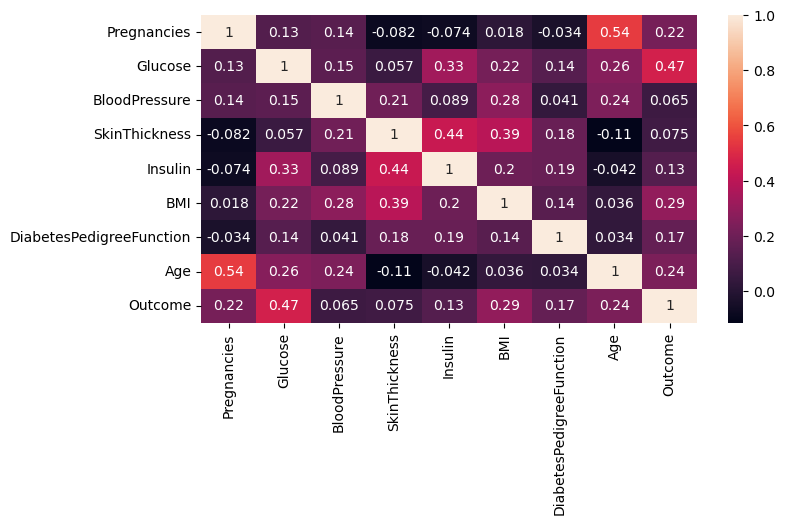

In [8]:
# Plot data as a color-encoded correlation matrix
plt.subplots(figsize=(8,4))
sns.heatmap(correlation_matrix,
            xticklabels=correlation_matrix.columns,
            yticklabels=correlation_matrix.columns,
            annot=True)
plt.show()

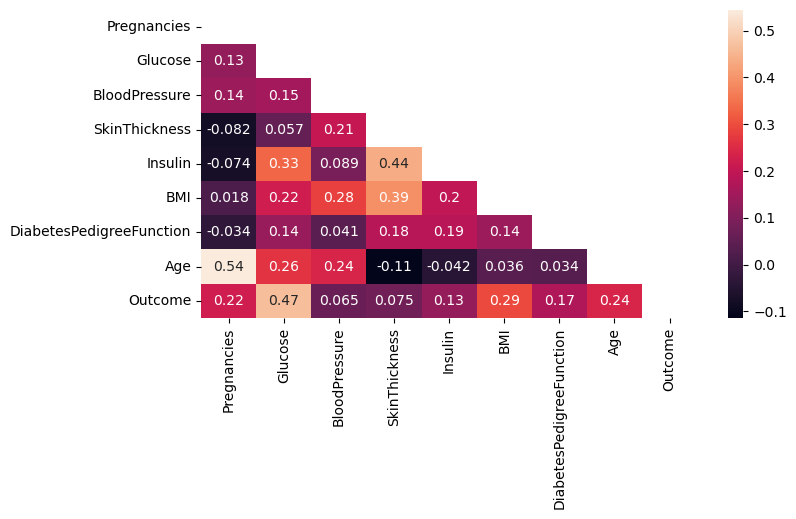

In [9]:
# Plot data as a color-encoded correlation matrix. Only display bottom triangle of matrix.
plt.subplots(figsize=(8,4))
mask = np.zeros_like(correlation_matrix, dtype=bool)
mask[np.triu_indices_from(mask)] = True
sns.heatmap(correlation_matrix,
            xticklabels=correlation_matrix.columns,
            yticklabels=correlation_matrix.columns,
            annot=True, mask=mask)
#plt.savefig('DiabetesCorrelationMatrix')
plt.show()

* Which two variables have the highest correlation?

The highest linear correlation is between Age and Pregnancies– moderate positive correlation(0.54). Which means as women's age increases, there are more pregnancies. Another moderate positive correlation is between the Glucose and Outcome (0.47), which means that individuals with higher glucose levels tend be more likely to have diabetes. There's another moderate positive relationship between SkinThikness and Insulin (0.44), which suggests that individuals with more SkinThikness tend to have higher insulin. 

In [9]:
# Review distribution of targets (outcome)
df['Outcome'].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

/var/folders/zg/g66yp7nj5kb_9dq675r__8t80000gp/T/ipykernel_2565/3314579724.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Outcome', data=df, palette='hls')


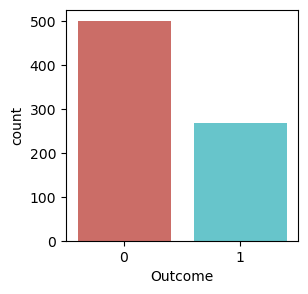

In [10]:
# Plot outcome counts
plt.subplots(figsize=(3,3))
sns.countplot(x='Outcome', data=df, palette='hls')
#plt.savefig('DiabetesOutcome_plot')
plt.show()

# Inference

In [11]:
model = smf.logit("Outcome	~ Pregnancies+Glucose+BloodPressure+SkinThickness+Insulin+BMI+DiabetesPedigreeFunction+Age", data=df).fit()

#view model summary
print(model.summary())

Optimization terminated successfully.
         Current function value: 0.470993
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                Outcome   No. Observations:                  768
Model:                          Logit   Df Residuals:                      759
Method:                           MLE   Df Model:                            8
Date:                Tue, 20 Oct 2026   Pseudo R-squ.:                  0.2718
Time:                        18:49:12   Log-Likelihood:                -361.72
converged:                       True   LL-Null:                       -496.74
Covariance Type:            nonrobust   LLR p-value:                 9.652e-54
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept                   -8.4047      0.717    -11.728      0.000      -9.809

* Pregnancies will have a positive influence on the probability of having a diabetes
* Glucose will have a positive influence on the probability of having a diabetes
* BloodPressure will have a negative influence on the probability of having a diabetes
* BMI will have a positive influence on the probability of having a diabetes
* DiabetesPedigreeFunction will have a positive influence on the probability of having a diabetes

## Prediction


### Prepare data

In [14]:
# Separate independent and dependent variables
X = df.iloc[:, :-1]     # feature values - all columns except last one
y = df.iloc[:, -1]      # target values - last column of data frame

In [15]:
X.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33


#### Normalization and Standardization is needed to deal with variables in different units

In [16]:
# Normalize data values.  Technique used is called min-max normalization.
X_normalized = (X - X.min()) / (X.max() - X.min())

In [17]:
X_normalized.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,0.352941,0.743719,0.590164,0.353535,0.000000,0.500745,0.234415,0.483333
1,0.058824,0.427136,0.540984,0.292929,0.000000,0.396423,0.116567,0.166667
2,0.470588,0.919598,0.524590,0.000000,0.000000,0.347243,0.253629,0.183333
3,0.058824,0.447236,0.540984,0.232323,0.111111,0.418778,0.038002,0.000000
4,0.000000,0.688442,0.327869,0.353535,0.198582,0.642325,0.943638,0.200000


In [18]:
# Standardize data values.  Technique used is called mean normalization.
X_standardized = (X - X.mean()) / X.std()

In [20]:
X_standardized.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,0.639530,0.847771,0.149543,0.906679,-0.692439,0.203880,0.468187,1.425067
1,-0.844335,-1.122665,-0.160441,0.530556,-0.692439,-0.683976,-0.364823,-0.190548
2,1.233077,1.942458,-0.263769,-1.287373,-0.692439,-1.102537,0.604004,-0.105515
3,-0.844335,-0.997558,-0.160441,0.154433,0.123221,-0.493721,-0.920163,-1.040871
4,-1.141108,0.503727,-1.503707,0.906679,0.765337,1.408828,5.481337,-0.020483


#### We could use either the normalized or standardized data values for model training
Note: The training set data could be normalized or standardized, but NOT both

In [23]:
# Split data into 75% training and 25% testing
X_train, X_test, y_train, y_test = \
    train_test_split(X_normalized, y, test_size=0.25, random_state=42)

### Train model

In [24]:
# Train logisitic regression model
model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

#### For binary-class (exactly 2 classes) problems, logistic regression creates one classifier
* For example, in this case where the dataset has exactly 2 classes, sklearn's LogisticRegression creates 1 classifier with 1 intercept and 1 set of coefficents.

In [25]:
print(f"\nclasses: {model.classes_}\n")
print(f"number of features: {model.n_features_in_}\n")
print(f"features: {model.feature_names_in_}\n")
print(f"intercept: {model.intercept_}\n")
print(f"coefficents: {model.coef_}")


classes: [0 1]

number of features: 8

features: ['Pregnancies' 'Glucose' 'BloodPressure' 'SkinThickness' 'Insulin' 'BMI'
 'DiabetesPedigreeFunction' 'Age']

intercept: [-5.54413997]

coefficents: [[ 0.93431666  4.50136896 -0.44240887  0.38505224 -0.10837001  3.18781744
   0.90563703  1.74505651]]


### Test model

In [27]:
# Generate predictions against the test set, predicted Y on the test data
predictions = model.predict(X_test)

### Model evaluation
#### Model performance to be discussed later in this class

In [28]:
# Calculate model accuracy
accuracy = model.score(X_test, y_test)
print("accuracy =", round((accuracy * 100), 2), "%")

accuracy = 74.48 %


In [ ]:
# Another way to calcuate accuracy rate is


In [29]:
from sklearn.metrics import accuracy_score

In [30]:

print(f"Accuracy = {round((accuracy_score(y_test, predictions) * 100), 4)}%")

Accuracy = 74.4792%


In [31]:
# Print classification report
#  Check precision, recall, f1-score
target_names = ['without diabetes', 'with diabetes']
print(classification_report(y_test, predictions, target_names=target_names))

                  precision    recall  f1-score   support

without diabetes       0.78      0.85      0.81       123
   with diabetes       0.67      0.57      0.61        69

        accuracy                           0.74       192
       macro avg       0.72      0.71      0.71       192
    weighted avg       0.74      0.74      0.74       192



In [32]:

print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.78      0.85      0.81       123
           1       0.67      0.57      0.61        69

    accuracy                           0.74       192
   macro avg       0.72      0.71      0.71       192
weighted avg       0.74      0.74      0.74       192



In [33]:
# Print confusion matrix
cnf_matrix = confusion_matrix(y_test, predictions)
cnf_matrix

array([[104,  19],
       [ 30,  39]])

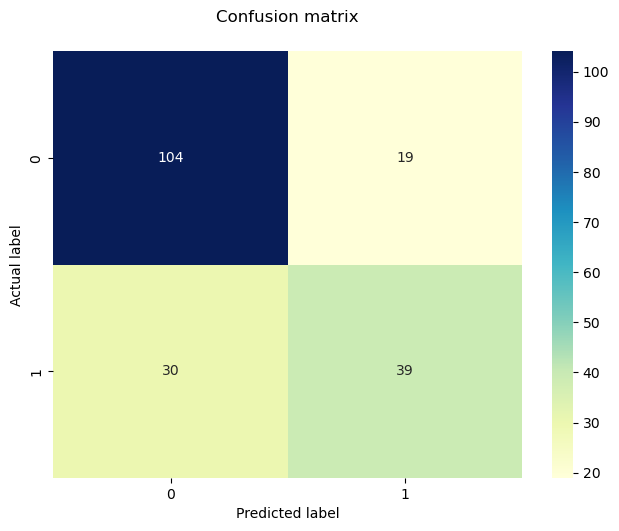

In [34]:
# Visualize Confusion Matrix using Heatmap
class_names=[0,1] # name  of classes
fig, ax = plt.subplots()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)

# Create heatmap
sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, cmap="YlGnBu" ,fmt='g')
#ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion matrix', y=1.05)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

##### This confusion matrix is a little different than what we see in the slides


#####  Let us see what number is true positive, what is true negative? what is false positive and what is false negative?

##### true positive=39, false positive=19, true negative=104, fasle negative=30

##### So what is precision, recall, accuracy rate?
##### precision=true positive/(true pos+false pos)=39/(39+19)=0.6724
##### recall=true positive/(true pos+false neg)=39/(39+30)=0.57
##### accuracy=(true positive+true negative)/all=(39+104)/(39+19+104+30)=143/192=0.744792
#####  F1-SCORE= 2*Precision*Recall/(Precision+Recall)=2*0.6724*0.57/(0.6724+0.57)=0.61

In [35]:
2*0.6724*0.57/(0.6724+0.57)

0.6169800386349001

In [36]:
# Display the probability of each class for each data instance
model.predict_proba(X_test)

array([[0.67099351, 0.32900649],
       [0.79004181, 0.20995819],
       [0.84930414, 0.15069586],
       [0.75520724, 0.24479276],
       [0.52360386, 0.47639614],
       [0.54250637, 0.45749363],
       [0.94804164, 0.05195836],
       [0.57264373, 0.42735627],
       [0.48809393, 0.51190607],
       [0.33008082, 0.66991918],
       [0.67898463, 0.32101537],
       [0.18878052, 0.81121948],
       [0.59900481, 0.40099519],
       [0.67111576, 0.32888424],
       [0.87108044, 0.12891956],
       [0.64138001, 0.35861999],
       [0.82804405, 0.17195595],
       [0.86273602, 0.13726398],
       [0.34243306, 0.65756694],
       [0.56978381, 0.43021619],
       [0.73158754, 0.26841246],
       [0.85990401, 0.14009599],
       [0.50187803, 0.49812197],
       [0.85778407, 0.14221593],
       [0.48792973, 0.51207027],
       [0.23116588, 0.76883412],
       [0.80994567, 0.19005433],
       [0.90865247, 0.09134753],
       [0.74563185, 0.25436815],
       [0.81176099, 0.18823901],
       [0.

* How to explain ROC curve and AUC?

### Understand how the features influenced the model

In [37]:
# Extract feature names
labels = list(X_train.columns)
labels

['Pregnancies',
 'Glucose',
 'BloodPressure',
 'SkinThickness',
 'Insulin',
 'BMI',
 'DiabetesPedigreeFunction',
 'Age']

In [38]:
coeff = list(model.coef_[0])
coeff

[np.float64(0.9343166645273874),
 np.float64(4.501368955272963),
 np.float64(-0.4424088694337519),
 np.float64(0.3850522353433936),
 np.float64(-0.10837001381661582),
 np.float64(3.187817438274161),
 np.float64(0.9056370254817628),
 np.float64(1.7450565108287592)]

Text(0.5, 0, 'Importance')

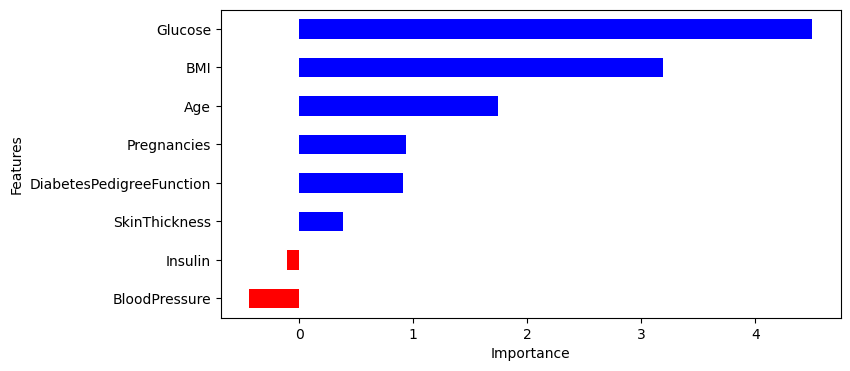

In [39]:
# Visualize how the model uses different features and which features have greater effect
features = pd.DataFrame()
features['Features'] = labels
features['importance'] = coeff
features.sort_values(by=['importance'], ascending=True, inplace=True)
features['positive'] = features['importance'] > 0
features.set_index('Features', inplace=True)
features.importance.plot(kind='barh', figsize=(8, 4),
                         color = features.positive.map({True: 'blue', False: 'red'}))
plt.xlabel('Importance')

# [9660] K-Nearest Neighbor 1
Data file:
* https://raw.githubusercontent.com/vjavaly/Baruch-CIS-9660/main/data/bmi.csv

In [40]:
from datetime import datetime
print(f'Run time: {datetime.now().strftime("%D %T")}')

Run time: 10/20/26 19:59:22


### Import libraries

In [41]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

### Load data

In [42]:
# Load data file (bmi.csv) into dataframe
df = pd.read_csv('https://raw.githubusercontent.com/vjavaly/Baruch-CIS-STA-3920/main/data/bmi.csv')

### Examine data

In [43]:
df.shape

(19, 3)

#### 19*0.2=3.8~~4 as test set,, 15 as the training dataset

In [44]:
df.head(19)

,Height,Weight,BMI
0,150,45,Normal
1,155,70,Overweight
2,145,35,Underweight
3,160,55,Normal
4,140,50,Overweight
5,142,30,Underweight
6,152,65,Overweight
7,157,42,Underweight
8,147,42,Normal
9,150,50,Normal


NOTES
* Height is in centimeters and weight is in kilograms
* BMI is the target (dependent variable)

### Separate independent and dependent variables

In [45]:
df["BMI"].unique()

array(['Normal', 'Overweight', 'Underweight'], dtype=object)

In [46]:
X = df.drop('BMI', axis = 1)
X.head()

,Height,Weight
0,150,45
1,155,70
2,145,35
3,160,55
4,140,50


In [47]:
y = df['BMI']
y.head()

0         Normal
1     Overweight
2    Underweight
3         Normal
4     Overweight
Name: BMI, dtype: object

### Normalize independent variables

In [48]:
min_max_scaler = MinMaxScaler()
X_scaled = min_max_scaler.fit_transform(X)
X_scaled

array([[0.5       , 0.43478261],
       [0.75      , 0.97826087],
       [0.25      , 0.2173913 ],
       [1.        , 0.65217391],
       [0.        , 0.54347826],
       [0.1       , 0.10869565],
       [0.6       , 0.86956522],
       [0.85      , 0.36956522],
       [0.35      , 0.36956522],
       [0.5       , 0.54347826],
       [0.25      , 0.76086957],
       [0.75      , 0.32608696],
       [0.6       , 0.54347826],
       [0.25      , 0.97826087],
       [0.        , 0.        ],
       [0.35      , 0.08695652],
       [0.45      , 1.        ],
       [0.85      , 0.73913043],
       [0.65      , 0.26086957]])

### Split data into training and test sets

In [49]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

### Train model (using default hyperparameters)

In [50]:
knn = KNeighborsClassifier()
knn.get_params()

{'algorithm': 'auto',
 'leaf_size': 30,
 'metric': 'minkowski',
 'metric_params': None,
 'n_jobs': None,
 'n_neighbors': 5,
 'p': 2,
 'weights': 'uniform'}

In [51]:
knn.fit(X_train, y_train)

KNeighborsClassifier()

### Calculate accuracy score

In [52]:
# Predict using the test set
y_pred = knn.predict(X_test)

In [53]:
# Print model accuracy score
accuracy_score_1 = accuracy_score(y_test, y_pred)
print(f"Accuracy = {round((accuracy_score_1 * 100), 4)}%")

Accuracy = 50.0%


### Train model with different hyperparameters

In [54]:
knn = KNeighborsClassifier(n_neighbors=5, weights='distance', metric='manhattan')
knn.fit(X_train, y_train)

KNeighborsClassifier(metric='manhattan', weights='distance')

### Calculate accuracy score

In [55]:
# Predict using the test set
y_pred = knn.predict(X_test)

In [56]:
# Print model accuracy score
accuracy_score_1 = accuracy_score(y_test, y_pred)
print(f"Accuracy = {round((accuracy_score_1 * 100), 4)}%")

Accuracy = 100.0%


In [57]:
# Print confusion matrix
cnf_matrix = confusion_matrix(y_test, y_pred)
cnf_matrix

array([[1, 0, 0],
       [0, 1, 0],
       [0, 0, 2]])

##### Training a heavy model on a small dataset, all from the same distribution, could cause an overfit.

# [9660] K-Nearest Neighbor 2
Data file:
* https://raw.githubusercontent.com/vjavaly/Baruch-CIS-9660/main/data/breast_cancer_diagnosis.csv

In [58]:
from datetime import datetime
print(f'Run time: {datetime.now().strftime("%D %T")}')

Run time: 10/20/26 20:16:17


### Import libraries

In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

### Load data

In [60]:
# Lad data file (breast_cancer_diagnosis.csv) into dataframe
df = pd.read_csv('https://raw.githubusercontent.com/vjavaly/Baruch-CIS-STA-3920/main/data/breast_cancer_diagnosis.csv')
df.shape

(569, 13)

In [61]:
df.head(100)

,id,name,radius,texture,perimeter,area,smoothness,compactness,concavity,symmetry,fractal_dimension,age,diagnosis
0,ID842302,Glynnis Munson,NaN,10.38,122.80,1001.0,0.11840,0.27760,0.300100,0.2419,0.07871,35,1
1,ID842517,Lana Behrer,20.570,17.77,132.90,1326.0,0.08474,0.07864,0.086900,0.1812,0.05667,27,1
2,ID84300903,Devondra Vanvalkenburgh,19.690,21.25,130.00,1203.0,0.10960,0.15990,0.197400,0.2069,0.05999,31,1
3,ID84348301,Glory Maravalle,NaN,20.38,77.58,386.1,0.14250,0.28390,0.241400,0.2597,0.09744,49,1
4,ID84358402,Mellie Mccurdy,20.290,14.34,135.10,1297.0,0.10030,0.13280,0.198000,0.1809,0.05883,20,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,ID86208,Reta Castiglioni,20.260,23.03,132.40,1264.0,0.09078,0.13130,0.146500,0.2095,0.05649,58,1
96,ID86211,Mariejeanne Hills,12.180,17.84,77.79,451.1,0.10450,0.07057,0.024900,0.1900,0.06635,60,0
97,ID862261,Eudora Treasure,9.787,19.94,62.11,294.5,0.10240,0.05301,0.006829,0.1350,0.06890,62,0
98,ID862485,Thea Rosser,11.600,12.84,74.34,412.6,0.08983,0.07525,0.041960,0.1620,0.06582,41,0


### Prepare data

In [62]:
# Check for missing values
df.isnull().sum()

id                    0
name                  0
radius               71
texture               0
perimeter             0
area                  0
smoothness            0
compactness           0
concavity             0
symmetry              0
fractal_dimension     0
age                   0
diagnosis             0
dtype: int64

In [63]:
# Replace missing values with column average
df["radius"].fillna(df["radius"].mean(), inplace=True)

/var/folders/zg/g66yp7nj5kb_9dq675r__8t80000gp/T/ipykernel_2565/413954924.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["radius"].fillna(df["radius"].mean(), inplace=True)


In [64]:
# Recheck for missing values
df.isnull().sum()

id                   0
name                 0
radius               0
texture              0
perimeter            0
area                 0
smoothness           0
compactness          0
concavity            0
symmetry             0
fractal_dimension    0
age                  0
diagnosis            0
dtype: int64

In [65]:
# Drop non-numeric variables
df.drop(["id", "name"], axis=1, inplace=True)
df.head()

,radius,texture,perimeter,area,smoothness,compactness,concavity,symmetry,fractal_dimension,age,diagnosis
0,14.326635,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.2419,0.07871,35,1
1,20.570000,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.1812,0.05667,27,1
2,19.690000,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.2069,0.05999,31,1
3,14.326635,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.2597,0.09744,49,1
4,20.290000,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.1809,0.05883,20,1


### Separate independent and dependent variables

In [66]:
X = df.drop("diagnosis", axis = 1)
y = df["diagnosis"]

### Standardize independent variables

In [67]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled

array([[ 0.00000000e+00, -2.07333501e+00,  1.26993369e+00, ...,
         2.21751501e+00,  2.25574689e+00, -3.28667534e-01],
       [ 1.90491532e+00, -3.53632408e-01,  1.68595471e+00, ...,
         1.39236330e-03, -8.68652457e-01, -9.17217738e-01],
       [ 1.63641823e+00,  4.56186952e-01,  1.56650313e+00, ...,
         9.39684817e-01, -3.98007910e-01, -6.22942636e-01],
       ...,
       [ 6.93627295e-01,  2.04557380e+00,  6.72675785e-01, ...,
        -8.09117071e-01, -8.95586935e-01, -1.35863039e+00],
       [ 1.91406863e+00,  2.33645719e+00,  1.98252415e+00, ...,
         2.13719425e+00,  1.04369542e+00,  1.12745118e-01],
       [-2.00354806e+00,  1.22179204e+00, -1.81438851e+00, ...,
        -8.20069901e-01, -5.61032377e-01, -1.81529984e-01]])

### Split data into training and test sets

In [68]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.25, random_state=42)

In [69]:
569*0.25


142.25

### Train model

* KNeighborsClassifier() default size k=5

In [70]:
knn = KNeighborsClassifier()
knn.get_params()

{'algorithm': 'auto',
 'leaf_size': 30,
 'metric': 'minkowski',
 'metric_params': None,
 'n_jobs': None,
 'n_neighbors': 5,
 'p': 2,
 'weights': 'uniform'}

In [71]:
knn = KNeighborsClassifier(weights='distance', metric='cosine')
knn.get_params()

{'algorithm': 'auto',
 'leaf_size': 30,
 'metric': 'cosine',
 'metric_params': None,
 'n_jobs': None,
 'n_neighbors': 5,
 'p': 2,
 'weights': 'distance'}

In [72]:
knn.fit(X_train, y_train)

KNeighborsClassifier(metric='cosine', weights='distance')

### Calculate accuracy score

In [73]:
y_pred=knn.predict(X_test)
print(f"Accuracy = {round((accuracy_score(y_test, y_pred) * 100), 4)}%")

Accuracy = 97.2028%


In [74]:
# Print confusion matrix
cnf_matrix = confusion_matrix(y_test, y_pred)
cnf_matrix

array([[88,  1],
       [ 3, 51]])

### Find best k value

In [75]:
# Set up array of possible k values
possible_k = np.arange(3,30,2)
possible_k

array([ 3,  5,  7,  9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29])

In [76]:
# Calculate accuracy for each k value
ac_scores=[]
for k in possible_k:
    knn=KNeighborsClassifier(n_neighbors=k, weights='distance', metric='cosine')
    knn.fit(X_train,y_train)
    y_pred=knn.predict(X_test)
    scores=round((accuracy_score(y_test, y_pred) * 100), 6)
    ac_scores.append(scores)
print ("Accuracy Scores :", ac_scores)

Accuracy Scores : [97.202797, 97.202797, 97.202797, 97.902098, 97.202797, 96.503497, 95.104895, 95.104895, 95.104895, 95.104895, 95.104895, 95.104895, 95.104895, 95.104895]


In [77]:
max_index = ac_scores.index(max(ac_scores))
best_k = possible_k[max_index]
print ("Best value of k is", best_k)

Best value of k is 9


### Plot Accuracy vs Number of Neighbors (k)

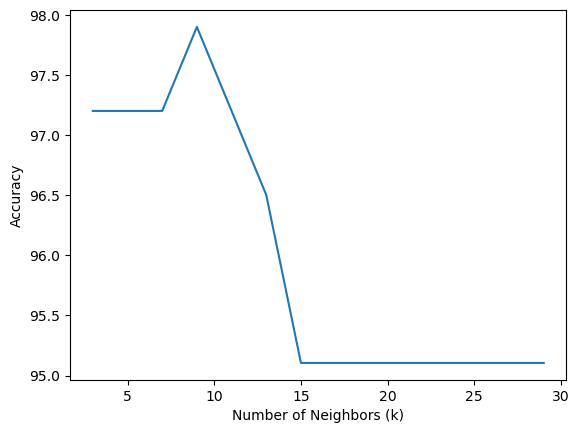

In [78]:
plt.plot(possible_k, ac_scores)
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Accuracy")
plt.show()